Quadratic equation solver. Conditional workflow here because based on the discriminant, you can either have two real roots, one repeated root, or no real roots. Only one of this will happen at a time, so conditional workflow works well here 

In [1]:
from typing import TypedDict, Literal

from langgraph.graph import END, START, StateGraph

In [2]:
class QuadraticState(TypedDict):
    a: int
    b: int
    c: int
    equation: str
    d: float
    x1: float | str
    x2: float | str

In [3]:
from math import sqrt

def show_equation(state: QuadraticState):
    equation = f"{state['a']}x^2 + {state['b']}x + {state['c']}"

    print(equation)
    return {'equation': equation}


def calculate_discriminant(state: QuadraticState):
    b = state['b']
    a = state['a']
    c = state['c']
    d = (b**2) - (4*a*c)

    return {'d': round(d, 3)}


def calculate_distinct_roots(state: QuadraticState):
    x1 = (-state['b'] + sqrt(state['d'])) / (2*state['a'])
    x2 = (-state['b'] - sqrt(state['d'])) / (2*state['a'])

    return {'x1':round(x1, 3), 'x2':round(x2, 3)}


def calculate_repeated_root(state: QuadraticState):
    x1 = -state['b'] / (2*state['a'])
    x2 = x1

    return {'x1':round(x1, 3), 'x2':round(x2, 3)}


def calculate_imaginary_roots(state: QuadraticState):
    x1 = 'NA'
    x2 = 'NA'

    return {'x1':x1, 'x2':x2}


In [4]:
# condition checking function
def check_condition(state: QuadraticState) -> Literal['calculate_distinct_roots', 'calculate_repeated_root', 'calculate_imaginary_roots']:
    d = state['d']

    if d > 0:
        return 'calculate_distinct_roots'
    elif d == 0:
        return 'calculate_repeated_root'
    else:
        return 'calculate_imaginary_roots'

In [5]:
graph = StateGraph(QuadraticState)

graph.add_node('show_equation', show_equation)
graph.add_node('calculate_discriminant', calculate_discriminant)
graph.add_node('calculate_distinct_roots', calculate_distinct_roots)
graph.add_node('calculate_repeated_root', calculate_repeated_root)
graph.add_node('calculate_imaginary_roots', calculate_imaginary_roots)

graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calculate_discriminant')
graph.add_conditional_edges('calculate_discriminant', check_condition)
graph.add_edge('calculate_distinct_roots', END)
graph.add_edge('calculate_repeated_root', END)
graph.add_edge('calculate_imaginary_roots', END)

workflow = graph.compile()

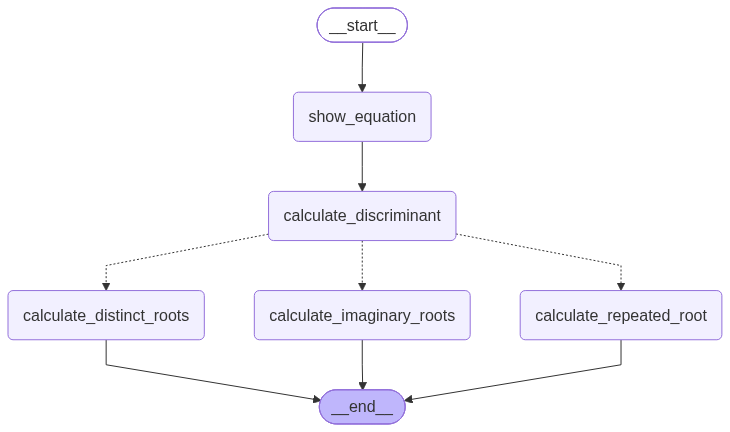

In [6]:
workflow

In [12]:
initial_state = {
    'a': 10,
    'b': -3,
    'c': -4
}

output_state = workflow.invoke(initial_state) #type: ignore

10x^2 + -3x + -4


In [13]:
output_state

{'a': 10,
 'b': -3,
 'c': -4,
 'equation': '10x^2 + -3x + -4',
 'd': 169,
 'x1': 0.8,
 'x2': -0.5}